In [1]:
import ast
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wfdb

from pathlib import Path

In [2]:
PROJECT_ROOT = Path("..")

PTBXL_DIR = PROJECT_ROOT / "data" / "raw" / "ptb-xl"

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

REPORTS_DIR = PROJECT_ROOT / "reports"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("PTB-XL directory:")
print(PTBXL_DIR)

PTB-XL directory:
../data/raw/ptb-xl


In [3]:
df = pd.read_csv(PTBXL_DIR / "ptbxl_database.csv")

print("Shape:", df.shape)

df.head()

Shape: (21799, 28)


,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
0,1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
1,2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
2,3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
3,4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,...,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
4,5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,...,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr


In [4]:
print(df.columns.tolist())

['ecg_id', 'patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'validated_by', 'second_opinion', 'initial_autogenerated_report', 'validated_by_human', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr']


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21799 entries, 0 to 21798
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ecg_id                        21799 non-null  int64  
 1   patient_id                    21799 non-null  float64
 2   age                           21799 non-null  float64
 3   sex                           21799 non-null  int64  
 4   height                        6974 non-null   float64
 5   weight                        9421 non-null   float64
 6   nurse                         20326 non-null  float64
 7   site                          21782 non-null  float64
 8   device                        21799 non-null  str    
 9   recording_date                21799 non-null  str    
 10  report                        21799 non-null  str    
 11  scp_codes                     21799 non-null  str    
 12  heart_axis                    13331 non-null  str    
 13  infarction_s

In [6]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ecg_id,21799.0,NaN,NaN,NaN,10926.658379,6302.393366,1.0,5469.5,10926.0,16386.5,21837.0
patient_id,21799.0,NaN,NaN,NaN,11250.156521,6235.026404,302.0,5974.5,11419.0,16607.5,21797.0
age,21799.0,NaN,NaN,NaN,62.769301,32.308813,2.0,50.0,62.0,72.0,300.0
sex,21799.0,NaN,NaN,NaN,0.47915,0.499577,0.0,0.0,0.0,1.0,1.0
height,6974.0,NaN,NaN,NaN,166.702323,10.867321,6.0,160.0,166.0,174.0,209.0
weight,9421.0,NaN,NaN,NaN,70.995223,15.878803,5.0,60.0,70.0,80.0,250.0
nurse,20326.0,NaN,NaN,NaN,2.291745,3.254033,0.0,0.0,1.0,3.0,11.0
site,21782.0,NaN,NaN,NaN,1.544945,4.172883,0.0,0.0,1.0,2.0,50.0
device,21799,11,CS100 3,6140,NaN,NaN,NaN,NaN,NaN,NaN,NaN
recording_date,21799,21795,1992-02-06 11:47:42,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
missing = df.isna().sum().sort_values(ascending=False)

missing[missing > 0]

electrodes_problems    21769
infarction_stadium2    21696
pacemaker              21508
burst_noise            21186
baseline_drift         20201
extra_beats            19850
static_noise           18539
infarction_stadium1    16187
height                 14825
weight                 12378
validated_by            9378
heart_axis              8468
nurse                   1473
site                      17
dtype: int64

In [8]:
print("ECG recordings:", df["ecg_id"].nunique())

print("Unique patients:", df["patient_id"].nunique())

ECG recordings: 21799
Unique patients: 18869


In [9]:
recordings_per_patient = df.groupby("patient_id").size()

print(recordings_per_patient.describe())

count    18869.000000
mean         1.155281
std          0.523105
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         10.000000
dtype: float64


In [10]:
recordings_per_patient.value_counts().sort_index()

1     16758
2      1590
3       350
4        99
5        43
6        16
7         5
8         4
9         3
10        1
Name: count, dtype: int64

In [11]:
print(df["strat_fold"].value_counts().sort_index())

strat_fold
1     2175
2     2181
3     2192
4     2174
5     2174
6     2173
7     2176
8     2173
9     2183
10    2198
Name: count, dtype: int64


In [12]:
fold_distribution = df["strat_fold"].value_counts(normalize=True).sort_index() * 100

fold_distribution.round(2)

strat_fold
1      9.98
2     10.01
3     10.06
4      9.97
5      9.97
6      9.97
7      9.98
8      9.97
9     10.01
10    10.08
Name: proportion, dtype: float64

In [13]:
patient_fold_counts = df.groupby("patient_id")["strat_fold"].nunique()

print("Patients appearing in multiple folds:", (patient_fold_counts > 1).sum())

Patients appearing in multiple folds: 0


In [14]:
print(df["scp_codes"].iloc[0])

{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}


In [15]:
df["scp_codes_dict"] = df["scp_codes"].apply(ast.literal_eval)

In [16]:
df[["ecg_id", "scp_codes", "scp_codes_dict"]].head()

,ecg_id,scp_codes,scp_codes_dict
0,1,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}","{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}"
1,2,"{'NORM': 80.0, 'SBRAD': 0.0}","{'NORM': 80.0, 'SBRAD': 0.0}"
2,3,"{'NORM': 100.0, 'SR': 0.0}","{'NORM': 100.0, 'SR': 0.0}"
3,4,"{'NORM': 100.0, 'SR': 0.0}","{'NORM': 100.0, 'SR': 0.0}"
4,5,"{'NORM': 100.0, 'SR': 0.0}","{'NORM': 100.0, 'SR': 0.0}"


In [17]:
scp_counts = {}

for codes in df["scp_codes_dict"]:

    for code in codes.keys():

        scp_counts[code] = scp_counts.get(code, 0) + 1

scp_counts = pd.Series(scp_counts).sort_values(ascending=False)

scp_counts.head(20)

SR       16748
NORM      9514
ABQRS     3327
IMI       2676
ASMI      2357
LVH       2132
NDT       1825
LAFB      1623
AFIB      1514
ISC_      1272
PVC       1143
IRBBB     1118
STD_      1009
VCLVH      875
STACH      826
1AVB       793
IVCD       787
SARRH      772
NST_       767
ISCAL      659
dtype: int64

In [18]:
scp = pd.read_csv(PTBXL_DIR / "scp_statements.csv", index_col=0)

print("Shape:", scp.shape)

scp.head()

Shape: (71, 12)


,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
NDT,non-diagnostic T abnormalities,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,non-diagnostic T abnormalities,NaN,NaN,NaN,NaN
NST_,non-specific ST changes,1.0,1.0,NaN,STTC,NST_,Basic roots for coding ST-T changes and abnorm...,non-specific ST changes,145.0,MDC_ECG_RHY_STHILOST,NaN,NaN
DIG,digitalis-effect,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,suggests digitalis-effect,205.0,NaN,NaN,NaN
LNGQT,long QT-interval,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,long QT-interval,148.0,NaN,NaN,NaN
NORM,normal ECG,1.0,NaN,NaN,NORM,NORM,Normal/abnormal,normal ECG,1.0,NaN,NaN,F-000B7


In [19]:
scp[["description", "diagnostic", "diagnostic_class", "diagnostic_subclass"]].head(20)

,description,diagnostic,diagnostic_class,diagnostic_subclass
NDT,non-diagnostic T abnormalities,1.0,STTC,STTC
NST_,non-specific ST changes,1.0,STTC,NST_
DIG,digitalis-effect,1.0,STTC,STTC
LNGQT,long QT-interval,1.0,STTC,STTC
NORM,normal ECG,1.0,NORM,NORM
IMI,inferior myocardial infarction,1.0,MI,IMI
ASMI,anteroseptal myocardial infarction,1.0,MI,AMI
LVH,left ventricular hypertrophy,1.0,HYP,LVH
LAFB,left anterior fascicular block,1.0,CD,LAFB/LPFB
ISC_,non-specific ischemic,1.0,STTC,ISC_


In [20]:
scp["diagnostic_class"].value_counts(dropna=False)

diagnostic_class
NaN     27
MI      14
STTC    13
CD      11
HYP      5
NORM     1
Name: count, dtype: int64

In [21]:
diagnostic_mapping = scp[scp["diagnostic"] == 1]["diagnostic_class"].dropna().to_dict()

print("Diagnostic codes:", len(diagnostic_mapping))

Diagnostic codes: 44


In [22]:
def get_diagnostic_classes(codes, mapping):
    classes = set()

    for code in codes:

        diagnostic_class = mapping.get(code)

        if pd.notna(diagnostic_class):
            classes.add(diagnostic_class)

    return sorted(classes)

In [23]:
df["diagnostic_classes"] = df["scp_codes_dict"].apply(
    lambda x: get_diagnostic_classes(x, diagnostic_mapping)
)

In [24]:
df[["ecg_id", "diagnostic_classes"]].head(20)

,ecg_id,diagnostic_classes
0,1,[NORM]
1,2,[NORM]
2,3,[NORM]
3,4,[NORM]
4,5,[NORM]
5,6,[NORM]
6,7,[NORM]
7,8,[MI]
8,9,[NORM]
9,10,[NORM]


In [25]:
diagnostic_class_counts = {}

for classes in df["diagnostic_classes"]:

    for cls in classes:

        diagnostic_class_counts[cls] = diagnostic_class_counts.get(cls, 0) + 1

diagnostic_class_counts = pd.Series(diagnostic_class_counts).sort_values(
    ascending=False
)

diagnostic_class_counts

NORM    9514
MI      5469
STTC    5235
CD      4898
HYP     2649
dtype: int64

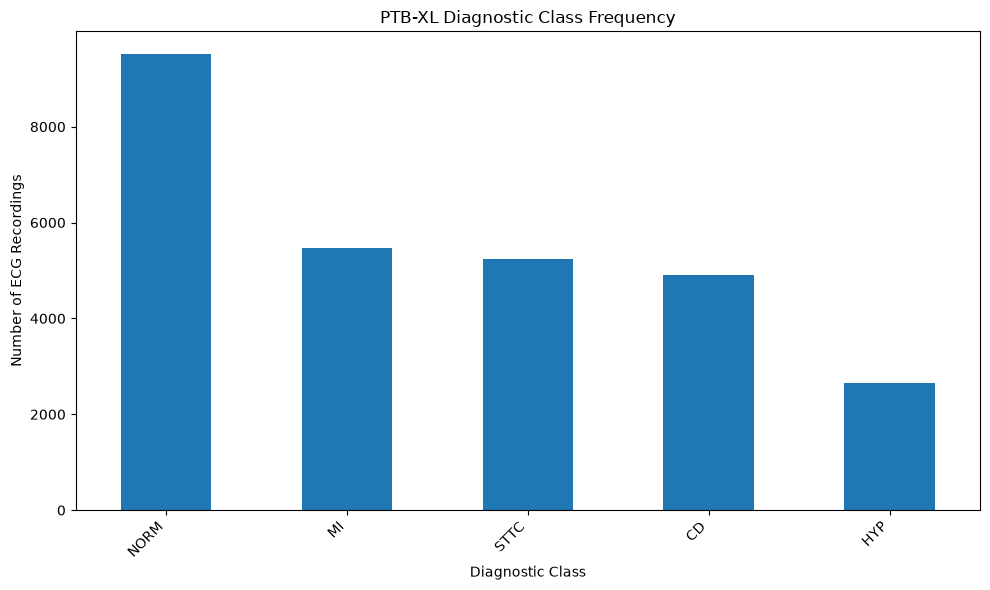

In [26]:
diagnostic_class_counts.plot(kind="bar", figsize=(10, 6))

plt.title("PTB-XL Diagnostic Class Frequency")

plt.xlabel("Diagnostic Class")

plt.ylabel("Number of ECG Recordings")

plt.xticks(
    rotation=45,
    ha="right",
)

plt.tight_layout()
plt.show()

In [27]:
print(df[["filename_lr", "filename_hr"]].head())

                 filename_lr                filename_hr
0  records100/00000/00001_lr  records500/00000/00001_hr
1  records100/00000/00002_lr  records500/00000/00002_hr
2  records100/00000/00003_lr  records500/00000/00003_hr
3  records100/00000/00004_lr  records500/00000/00004_hr
4  records100/00000/00005_lr  records500/00000/00005_hr


In [28]:
for column in ["filename_lr", "filename_hr"]:

    exists = df[column].apply(lambda x: (PTBXL_DIR / f"{x}.dat").exists())

    print(column, "existing:", exists.sum(), "/", len(exists))

filename_lr existing: 21799 / 21799
filename_hr existing: 21799 / 21799


In [29]:
record_path = PTBXL_DIR / df["filename_lr"].iloc[0]

record = wfdb.rdrecord(str(record_path))

print("Signal shape:", record.p_signal.shape)

print("Sampling frequency:", record.fs)

print("Channels:", record.sig_name)

Signal shape: (1000, 12)
Sampling frequency: 100
Channels: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


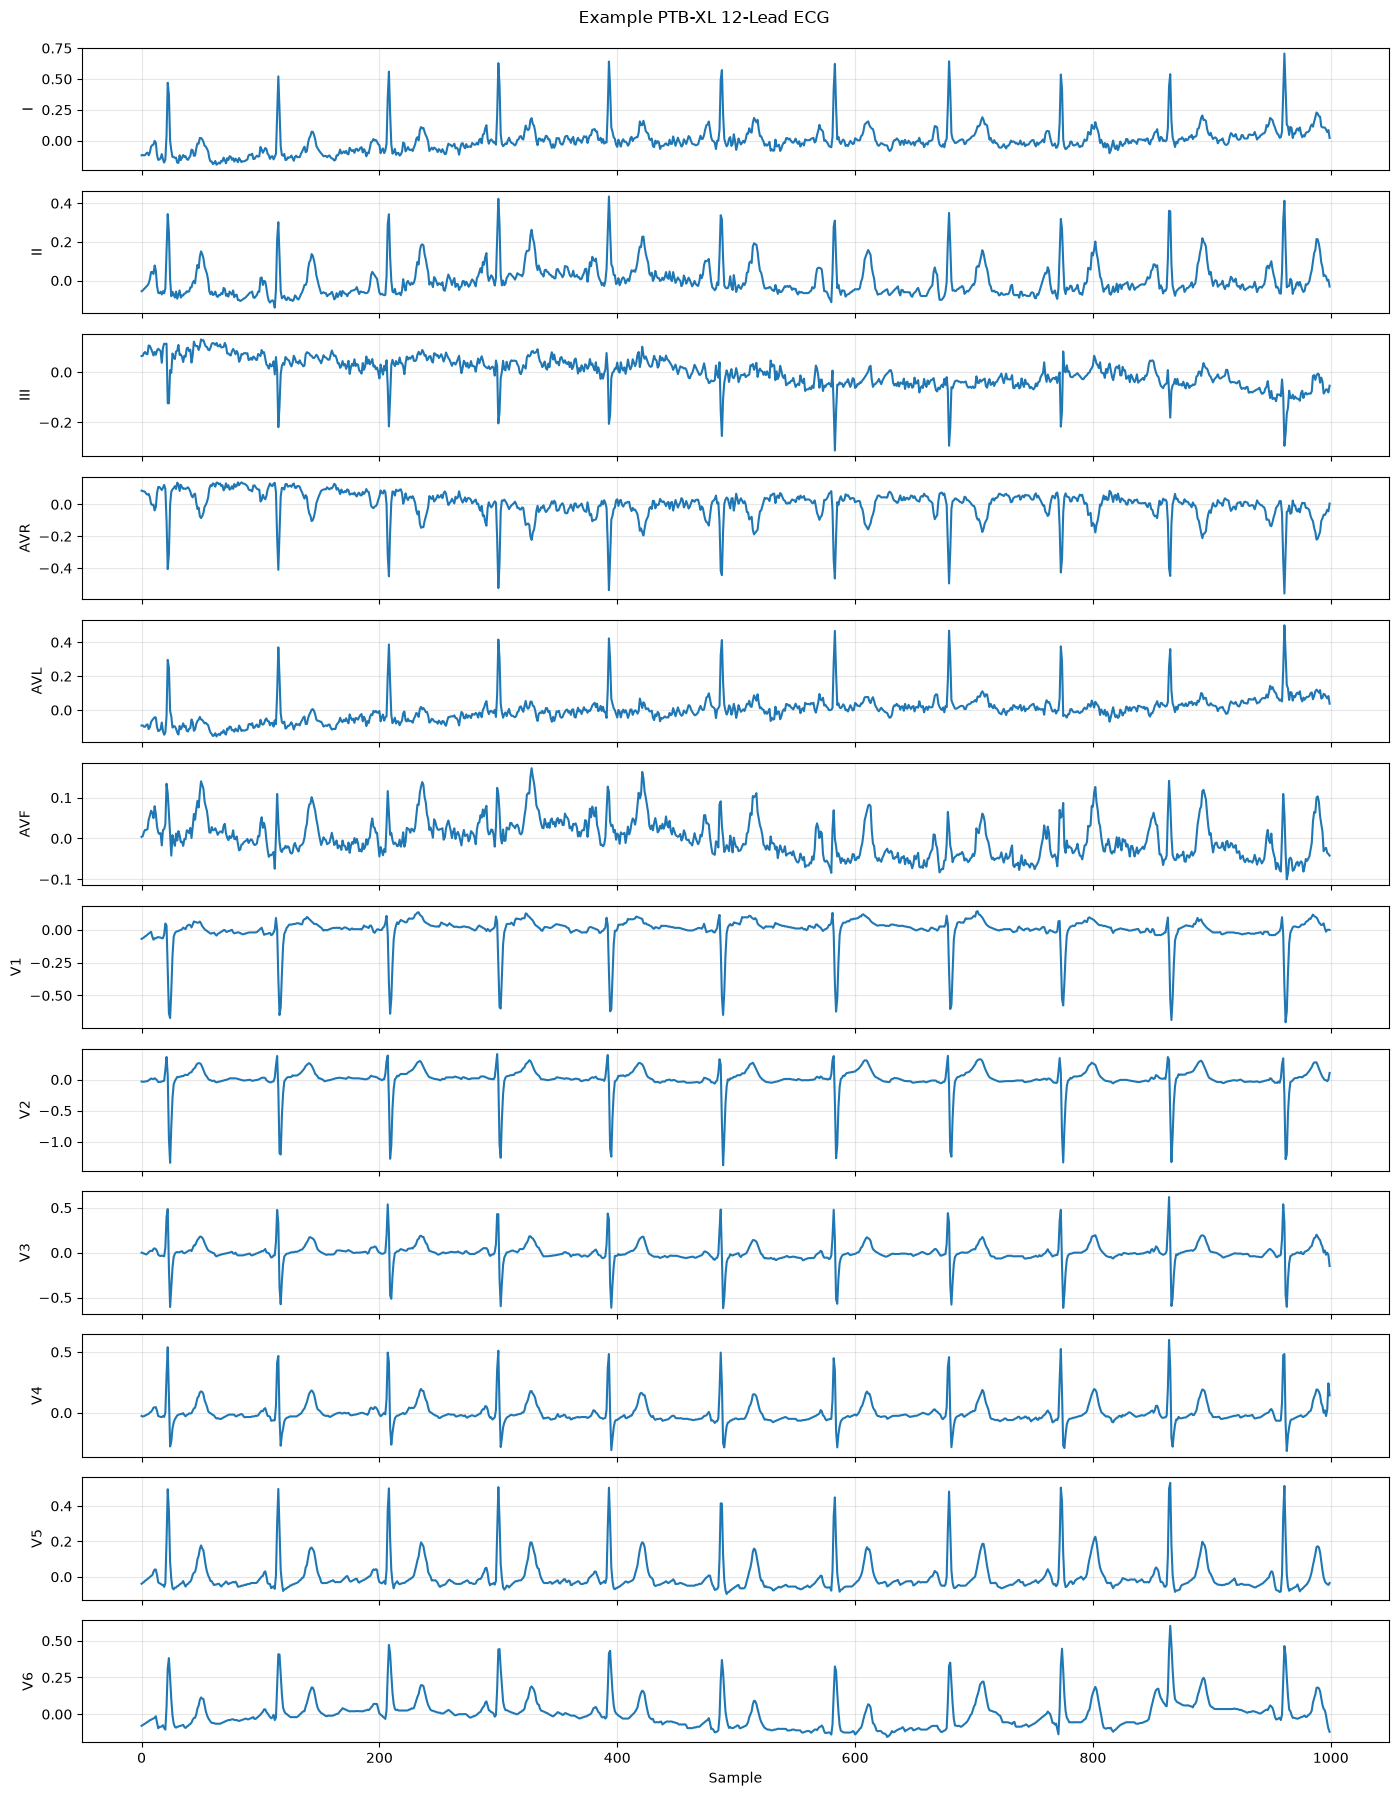

In [30]:
fig, axes = plt.subplots(12, 1, figsize=(14, 18), sharex=True)

for i, ax in enumerate(axes):

    ax.plot(record.p_signal[:, i])

    ax.set_ylabel(record.sig_name[i])

    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Sample")

fig.suptitle("Example PTB-XL 12-Lead ECG", y=0.995)

plt.tight_layout()
plt.show()

In [31]:
exploration_summary = {
    "n_recordings": int(df["ecg_id"].nunique()),
    "n_patients": int(df["patient_id"].nunique()),
    "n_diagnostic_codes": int(len(diagnostic_mapping)),
    "sampling_frequency_low_resolution": float(record.fs),
}

In [32]:
with open(REPORTS_DIR / "ptbxl_exploration_summary.json", "w") as f:
    json.dump(exploration_summary, f, indent=4)

In [33]:
metadata_output = PROCESSED_DIR / "ptbxl_metadata_explored.csv"

df.to_csv(metadata_output, index=False)

print("Saved:", metadata_output)

Saved: ../data/processed/ptbxl_metadata_explored.csv
